In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# Phân Tích Dữ Liệu Phát Hiện Tấn Công Web — CAPEC Multilabel Dataset

**Mục tiêu:**
- Hiểu cấu trúc của một HTTP Request
- Quan sát các loại tấn công Web phổ biến
- Làm sạch dữ liệu Web
- Trực quan hóa dữ liệu
- Tìm các dấu hiệu bất thường trong HTTP Request
- Xác định các đặc trưng thay đổi nhiều nhất khi bị tấn công

## Bước 1. Đọc dữ liệu
Bộ dữ liệu CAPEC chứa các HTTP Request gửi tới máy chủ Web.

Mỗi bản ghi có thể là:

- Truy cập bình thường
- SQL Injection
- Command Injection
- Path Traversal
- HTTP Request Smuggling
- ...

In [6]:
# ==========================================================
# IMPORT THƯ VIỆN
# ==========================================================

# Xử lý dữ liệu dạng bảng
import pandas as pd

# Tính toán số học
import numpy as np

# Trực quan hóa dữ liệu
import matplotlib.pyplot as plt
import seaborn as sns

# Quản lý đường dẫn tệp
from pathlib import Path

plt.style.use("default")
sns.set_theme(style="whitegrid")

In [7]:
# ==========================
# Đọc tập dữ liệu CAPEC
# ==========================

# Lấy thư mục làm việc hiện tại
# (thư mục chứa notebook hoặc script đang chạy)
root_folder = Path.cwd()

# Tạo đường dẫn tới file dữ liệu:
# root_folder/
# └── Dataset/
#     └── capec_small_multilabel2.csv
DATA_PATH = root_folder.parent / "Dataset" / "capec_small_multilabel2.csv"

# Đọc dữ liệu từ file CSV vào DataFrame
#
# low_memory=False:
# - Đọc toàn bộ dữ liệu trước khi suy luận kiểu dữ liệu
# - Giúp tránh cảnh báo DtypeWarning khi một cột chứa nhiều kiểu dữ liệu khác nhau
df_raw = pd.read_csv(DATA_PATH, low_memory=False)

# Hiển thị kích thước của tập dữ liệu
# shape = (số hàng, số cột)
print("Shape:", df_raw.shape)

# Hiển thị 5 dòng đầu tiên để kiểm tra dữ liệu đã được đọc đúng hay chưa
df_raw.head()

Shape: (10000, 38)


,timestamp,src_ip,src_port,dst_ip,dst_port,request_http_method,request_http_request,request_http_protocol,request_user_agent,request_referer,...,126 - Path Traversal,66 - SQL Injection,16 - Dictionary-based Password Attack,310 - Scanning for Vulnerable Software,153 - Input Data Manipulation,248 - Command Injection,274 - HTTP Verb Tampering,194 - Fake the Source of Data,34 - HTTP Response Splitting,33 - HTTP Request Smuggling
0,18/Jul/2020:05:53:55 +0200,172.26.0.1,57826.0,172.26.0.4,80.0,POST,/blog/wp-login.php?action=lostpassword,HTTP/1.1,Mozilla/5.0 (X11; Linux x86_64; rv:70.0) Gecko...,http://test-site.com/blog/wp-login.php?action=...,...,1,0,0,0,0,0,0,0,0,0
1,18/Jul/2020:05:27:30 +0200,172.26.0.1,57646.0,172.26.0.4,80.0,GET,/blog/wp-content/uploads%27%26cat+%2Fetc%2Fpas...,HTTP/1.1,Mozilla/5.0 (X11; Linux x86_64; rv:70.0) Gecko...,http://test-site.com/,...,0,0,0,0,0,0,0,0,0,0
2,29/Jul/2020:12:36:12 +0100,172.26.0.1,51184.0,172.26.0.4,80.0,GET,/,HTTP/1.1,Mozilla/5.0 (iPad; CPU OS 8_4_1 like Mac OS X)...,NaN,...,0,0,0,0,0,0,0,0,0,0
3,18/Jul/2020:06:02:09 +0200,172.26.0.1,64424.0,172.26.0.4,80.0,GET,/blog/index.php/2020/%2F%2F8501779237819759495...,HTTP/1.1,Mozilla/5.0 (X11; Linux x86_64; rv:70.0) Gecko...,NaN,...,0,0,0,0,0,0,0,0,0,0
4,29/Jul/2020:12:53:55 +0100,172.26.0.1,62044.0,172.26.0.4,80.0,GET,/,HTTP/1.1,Mozilla/5.0 (Windows NT 6.1; WOW64; Trident/7....,NaN,...,0,0,0,0,0,0,0,0,0,0


## Bước 2. Quan sát dữ liệu

In [8]:
# ==========================
# Kiểm tra thông tin tổng quan của tập dữ liệu
# ==========================

# info() hiển thị:
# - Số lượng mẫu (entries) trong DataFrame
# - Danh sách tất cả các cột và thứ tự của chúng
# - Số lượng giá trị không bị thiếu (Non-Null Count) của từng cột
# - Kiểu dữ liệu của từng cột (int64, float64, object,...)
# - Dung lượng bộ nhớ mà DataFrame đang sử dụng

print(df_raw.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 38 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   timestamp                               10000 non-null  object 
 1   src_ip                                  10000 non-null  object 
 2   src_port                                10000 non-null  float64
 3   dst_ip                                  10000 non-null  object 
 4   dst_port                                10000 non-null  float64
 5   request_http_method                     10000 non-null  object 
 6   request_http_request                    10000 non-null  object 
 7   request_http_protocol                   10000 non-null  object 
 8   request_user_agent                      9904 non-null   object 
 9   request_referer                         3624 non-null   object 
 10  request_host                            9995 non-null   obj

## Bước 3. Làm sạch dữ liệu

In [9]:
# ==========================
# Chuẩn bị nhãn phân loại
# ==========================

# Tạo một bản sao của DataFrame gốc để xử lý.
# Việc sử dụng copy() giúp tránh làm thay đổi dữ liệu ban đầu (df_raw).
df = df_raw.copy()

# Thay thế các giá trị thiếu (NaN) bằng chuỗi rỗng ("").
# Điều này giúp tránh lỗi ở các bước xử lý dữ liệu tiếp theo.
df = df.fillna("")

# ==========================
# Xác định các cột nhãn CAPEC
# ==========================

# Lấy danh sách các cột nhãn dạng one-hot encoding.
# Trong bộ dữ liệu này, các cột nhãn có tên chứa chuỗi " - ".
#
# Ví dụ:
# "100 - Overflow Buffers"
# "126 - Path Traversal"
# "242 - Code Injection"
label_cols = [c for c in df.columns if " - " in c]

# ==========================
# Chuyển one-hot thành một nhãn duy nhất
# ==========================

# idxmax(axis=1):
# - Tìm cột có giá trị lớn nhất trên từng hàng.
# - Với dữ liệu one-hot (0/1), cột có giá trị 1 sẽ được chọn.
# - Kết quả là tên của CAPEC tương ứng với mỗi mẫu.
#
# Ví dụ:
# 100 - Overflow Buffers    0
# 126 - Path Traversal      1
# 242 - Code Injection      0
#
# → Label = "126 - Path Traversal"
df["Label"] = df[label_cols].idxmax(axis=1)

# ==========================
# Kiểm tra phân bố nhãn
# ==========================

# Hiển thị tổng số mẫu trong tập dữ liệu
print("Số bản ghi:", len(df))

# Đếm số lượng mẫu thuộc từng nhãn CAPEC
df["Label"].value_counts()

Số bản ghi: 10000


000 - Normal                              5000
272 - Protocol Manipulation                672
66 - SQL Injection                         648
242 - Code Injection                       582
34 - HTTP Response Splitting               499
194 - Fake the Source of Data              499
88 - OS Command Injection                  494
126 - Path Traversal                       455
310 - Scanning for Vulnerable Software     440
274 - HTTP Verb Tampering                  391
153 - Input Data Manipulation              293
16 - Dictionary-based Password Attack       27
Name: Label, dtype: int64

Chuẩn hóa dữ liệu, Tạo các đặc trưng đơn giản từ dữ liệu Web.

# Bước 4 Trích xuất đặc trưng từ HTTP Request

In [10]:
# ==========================
# Trích xuất đặc trưng từ HTTP Request
# ==========================

# Tính độ dài của URL/Request Line
#
# request_http_request: chứa nội dung HTTP request
# astype(str): chuyển dữ liệu sang kiểu chuỗi để tránh lỗi nếu có giá trị số hoặc NaN
# str.len(): đếm số ký tự trong chuỗi
#
# Ý nghĩa:
# - Các cuộc tấn công như SQL Injection, Directory Traversal,
#   Command Injection thường tạo ra URL dài bất thường.
df["url_length"] = df["request_http_request"].astype(str).str.len()

# Tính độ dài của trường User-Agent
#
# User-Agent mô tả trình duyệt hoặc công cụ gửi request.
# Một số bot hoặc công cụ tấn công có User-Agent bất thường:
# - Rất ngắn
# - Rất dài
# - Chứa chuỗi đặc biệt
df["user_agent_length"] = df["request_user_agent"].astype(str).str.len()

# Tính độ dài của Cookie
#
# Cookie chứa thông tin phiên làm việc (session).
# Cookie dài bất thường có thể liên quan đến:
# - Session hijacking
# - Cookie poisoning
# - Payload được nhúng vào cookie
df["cookie_length"] = df["request_cookie"].astype(str).str.len()

# Tính độ dài của Request Body
#
# Request Body chứa dữ liệu được gửi trong các phương thức
# như POST, PUT,...
#
# Độ dài body lớn bất thường có thể xuất hiện trong:
# - SQL Injection
# - File Upload Attack
# - XML/JSON Injection
# - Command Injection
df["body_length"] = df["request_body"].astype(str).str.len()

# Hiển thị 5 dòng đầu tiên của các đặc trưng vừa tạo
# để kiểm tra kết quả trích xuất
df[["url_length", "user_agent_length", "cookie_length", "body_length"]].head()

,url_length,user_agent_length,cookie_length,body_length
0,38,68,438,88
1,122,68,444,0
2,1,107,0,0
3,99,68,442,0
4,1,80,0,0


## Bước 5. Biểu đồ chuỗi thời gian

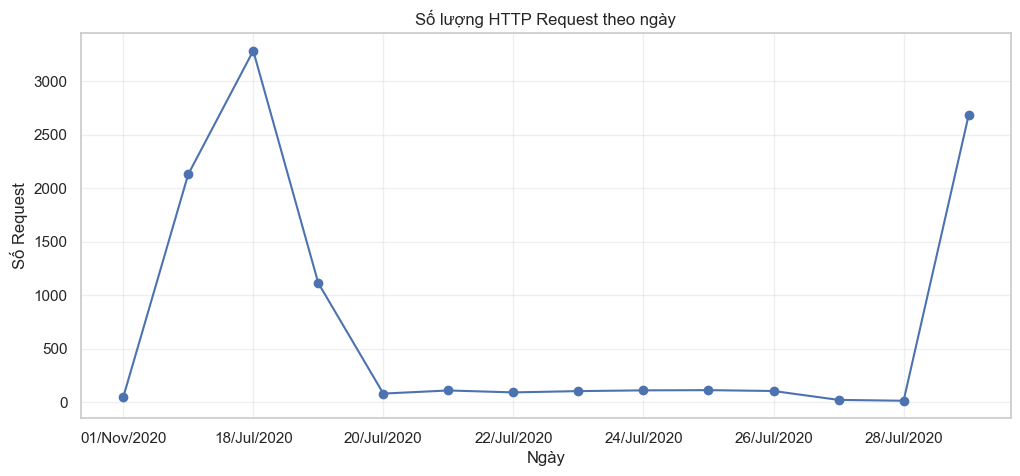

In [11]:
# ==========================
# Trích xuất đặc trưng độ dài từ HTTP request
# ==========================

# Lấy phần ngày từ timestamp để phân tích theo thời gian
#
# timestamp: chứa thời điểm ghi nhận request (dạng chuỗi hoặc datetime)
# astype(str): chuyển sang chuỗi để xử lý thống nhất
# str[:11]: lấy 11 ký tự đầu (thường tương ứng với phần ngày)
#
# Ví dụ:
# "2024-01-15 10:23:45" → "2024-01-15"
df["date"] = df["timestamp"].astype(str).str[:11]

# Đếm số lượng request theo từng ngày
#
# value_counts(): đếm số lần xuất hiện của mỗi ngày
# sort_index(): sắp xếp theo thứ tự thời gian (tăng dần)
daily_count = df["date"].value_counts().sort_index()

# ==========================
# Trực quan hóa lưu lượng theo thời gian
# ==========================

# Tạo khung hình biểu đồ với kích thước 12x5 inch
plt.figure(figsize=(12, 5))

# Vẽ biểu đồ đường thể hiện số request theo ngày
# marker="o": đánh dấu từng điểm dữ liệu trên đường biểu diễn
daily_count.plot(marker="o")

# Đặt tiêu đề biểu đồ
plt.title("Số lượng HTTP Request theo ngày")

# Nhãn trục X (thời gian)
plt.xlabel("Ngày")

# Nhãn trục Y (số lượng request)
plt.ylabel("Số Request")

# Bật lưới nhẹ để dễ quan sát xu hướng
plt.grid(alpha=0.3)

# Hiển thị biểu đồ
plt.show()